In [24]:
# Outlier exploration, lake 327 (chlorophyll-a)
## 1. Load the data and take a first lookimport numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# Extracted lake time series (lake 327, chlorophyll-a, daily maps)
path = r"C:\Users\zweifemo\coding\data\cci\327.nc"

# mask_and_scale=False keeps raw values, so missing data stays -9999
ds = xr.open_dataset(path, mask_and_scale=False)
ds

<xarray.Dataset> Size: 65MB
Dimensions:             (time: 3672, lat: 37, lon: 95)
Coordinates:
  * time                (time) float32 15kB 1.022e+09 1.022e+09 ... 1.704e+09
  * lat                 (lat) float32 148B 46.21 46.22 46.23 ... 46.5 46.5 46.51
  * lon                 (lon) float32 380B 6.146 6.154 6.162 ... 6.921 6.929
Data variables:
    chla                (time, lat, lon) float32 52MB ...
    lwlr_quality_flags  (time, lat, lon) int8 13MB ...
    summary             (lat, lon) float32 14kB ...
Attributes:
    variable:   chla
    qa:         lwlr_quality_flags
    qa_filter:  1
    shapefile:  C:\Users\schelian\cci-cyano-production\shapefiles\lakes_cci_v...

In [ ]:
# Convert the time axis (Unix seconds) to dates
t = pd.to_datetime(ds["time"].values, unit="s")
print(t.min(), t.max(), len(t)) # first day, last day, number of days
print(ds["chla"].shape) # (time, lat, lon)

2002-05-17 00:00:00 2023-12-29 00:00:00 3672
(3672, 37, 95)


In [ ]:
# Load chla into memory and replace the fill value -9999 with NaN
chla = ds["chla"].isel(time=slice(0, 50)).values
print(chla.dtype, chla.min(), chla.max())

float32 -9999.0 28.136696


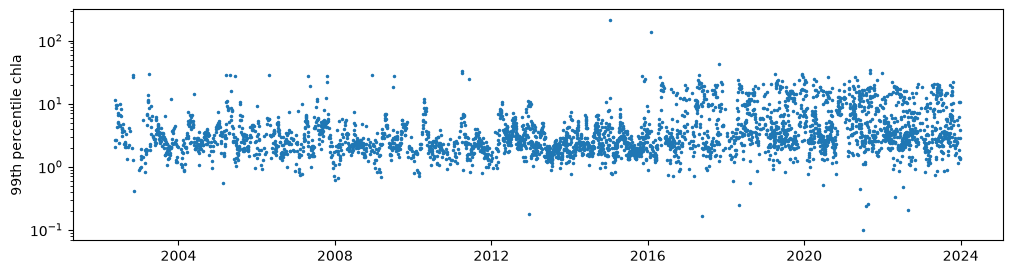

In [ ]:
# Load chla into memory and replace the fill value -9999 with NaN
data = ds["chla"].values.astype(float)
data[data == -9999] = np.nan

# Flatten each daily map (lat x lon) into one row: shape (time, pixels)
flat = data.reshape(data.shape[0], -1)

# 99th percentile over all pixels for each day
daily_p99 = np.nanpercentile(flat, 99, axis=1)

plt.figure(figsize=(12, 3))
plt.plot(t, daily_p99, ".", ms=3)
plt.yscale("log")
plt.ylabel("99th percentile chla")
plt.show()

In [25]:
## 2. Daily overview: which days stand out?
# One row per day: 99th percentile, largest pixel, number of valid pixels
n_valid = np.sum(~np.isnan(flat), axis=1)
df = pd.DataFrame({
    "date": t,
    "p99": daily_p99,
    "max": np.nanmax(flat, axis=1),
    "n_valid": n_valid,
})

print(df.sort_values("p99", ascending=False).head(10))  # highest days
print(df.sort_values("p99").head(10))                   # lowest days

           date         p99         max  n_valid
1802 2015-01-15  212.984070  688.071899      183
2038 2016-01-30  137.641429  139.367111      203
2330 2017-10-30   42.011165   55.645569       31
3134 2021-09-08   34.309766  490.908905      909
1042 2011-04-01   32.503311   36.082565      101
3132 2021-09-06   30.676548   54.663528      930
3194 2021-12-31   30.425050   47.605774       91
1043 2011-04-02   30.422895   45.208023      918
2722 2019-12-10   29.919532   47.205315      100
68   2003-03-31   29.902452   30.044783      241
           date       p99       max  n_valid
3082 2021-07-01  0.099452  0.099452        1
2243 2017-05-25  0.164144  0.164492        5
1339 2012-12-16  0.177802  0.177802       53
3374 2022-08-24  0.205554  0.206470        2
3100 2021-07-27  0.236782  0.237395        9
2384 2018-05-01  0.247111  0.247111        1
3115 2021-08-19  0.252878  0.252878        1
3276 2022-04-29  0.329893  0.331287        3
45   2002-11-08  0.404741  0.429653      216
3061 2021-0

In [26]:
# Spike indicator: how far is the single largest pixel above the p99?
df["max_over_p99"] = df["max"] / df["p99"]

# Ignore days with very few valid pixels (< 20): too little data to judge
print(df[df["n_valid"] >= 20]
      .sort_values("max_over_p99", ascending=False)
      .head(10))

           date        p99         max  n_valid  max_over_p99
2251 2017-06-11   3.452303  465.859589      924    134.941677
1356 2013-01-16   4.550001  427.508820      721     93.957959
3447 2023-01-07  18.604126  908.326294      768     48.823916
1342 2012-12-26   9.084246  334.174530      501     36.786162
2012 2015-12-10  24.854406  817.815430      552     32.904243
2555 2019-04-01   1.645647   52.059593      641     31.634718
1779 2014-12-09   4.844222  151.329239      682     31.239124
2647 2019-07-30   3.826837  104.874901      666     27.405112
1347 2013-01-02   5.246377  127.148331      702     24.235454
3601 2023-08-30   0.901123   20.310480      814     22.539065


2015-01-15 values: [ 91.85159302  91.85159302 212.98406982 212.98406982 688.07189941] flags: [0 0 0 0 0]
2016-01-30 values: [ 53.08301544  53.08301544 139.36711121 139.36711121 139.36711121] flags: [0 0 0 0 0]
2015-01-21 values: [2.78226733 2.78226733 6.06040859 6.06040859 6.06040859] flags: [0 0 0 0 0]


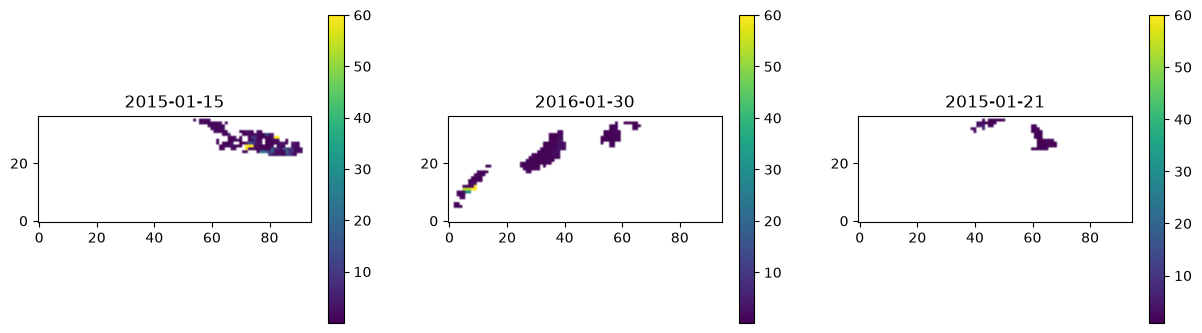

In [28]:
## 3. Look at single days: maps and quality flags
def day_index(date):
    """Index of the day in the file closest to the given date."""
    return int(np.abs(t - pd.Timestamp(date)).argmin())

# Two outlier days and one normal day nearby for comparison
days = ["2015-01-15", "2016-01-30", "2015-01-21"]
flags = ds["lwlr_quality_flags"].values

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, d in zip(axs, days):
    i = day_index(d)
    im = ax.imshow(data[i], origin="lower", vmax=60)  # cap color scale at 60
    ax.set_title(str(t[i].date()))
    plt.colorbar(im, ax=ax)

    # five largest pixels of the day and their quality flags
    top = np.argsort(np.nan_to_num(data[i].ravel(), nan=-1))[-5:]
    print(t[i].date(), "values:", data[i].ravel()[top], "flags:", flags[i].ravel()[top])
plt.show()

## 4. Select candidate outlier days

Compare each pixel with its own time series.
Flag unusually high observations, then rank candidate days by
their spatial chlorophyll-a range.

This ranking is a working interpretation of the task, not yet
a confirmed selection rule.

In [29]:
# Keep observations with quality flag 0.
flags = ds["lwlr_quality_flags"].values
d = data.copy()
d[flags != 0] = np.nan

# Calculate the mean and standard deviation over time for each pixel.
mu = np.nanmean(d, axis=0)
sd = np.nanstd(d, axis=0)

# A zero standard deviation cannot be used as a divisor.
sd_safe = np.where(sd > 0, sd, np.nan)

# Express each observation's distance above its pixel mean
# in units of that pixel's standard deviation.
z = (d - mu) / sd_safe

C:\Users\zweifemo\AppData\Local\Temp\ipykernel_29832\315997795.py:7: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(d, axis=0)
c:\Users\zweifemo\AppData\Local\miniforge3\envs\cci\Lib\site-packages\numpy\lib\nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [30]:
# One row per day, one column per grid pixel.
zflat = z.reshape(len(t), -1)
dflat = d.reshape(len(t), -1)

# Summarize unusually high observations for each day.
zmax = np.nanmax(zflat, axis=1)
n_out = np.sum(zflat > 3, axis=1)

# Spatial range: highest minus lowest valid value on the same day.
daily_range = (
    np.nanmax(dflat, axis=1)
    - np.nanmin(dflat, axis=1)
)

cand = pd.DataFrame({
    "date": t,
    "zmax": zmax,
    "n_pix_gt3": n_out,
    "range": daily_range,
})

print("Days with at least one pixel above 3 standard deviations:")
print(int((cand["zmax"] > 3).sum()))

print("\nDays with the largest spatial range:")
print(cand.sort_values("range", ascending=False).head(10))

Days with at least one pixel above 3 standard deviations:
1205

Days with the largest spatial range:
           date       zmax  n_pix_gt3       range
3447 2023-01-07  35.197730         74  908.242969
2012 2015-12-10  43.751967         13  817.802204
1802 2015-01-15  43.063263         27  688.071812
3134 2021-09-08  42.960854        383  490.681064
2251 2017-06-11  35.353992          1  465.753131
1356 2013-01-16  39.209858          4  427.508732
1988 2015-11-06  42.688537         20  416.331765
1342 2012-12-26  42.977952          9  334.152890
2022 2015-12-24  42.740919          7  201.839572
1779 2014-12-09  41.655206          2  151.329119


C:\Users\zweifemo\AppData\Local\Temp\ipykernel_29832\2577270331.py:6: RuntimeWarning: All-NaN slice encountered
  zmax = np.nanmax(zflat, axis=1)
C:\Users\zweifemo\AppData\Local\Temp\ipykernel_29832\2577270331.py:11: RuntimeWarning: All-NaN slice encountered
  np.nanmax(dflat, axis=1)
C:\Users\zweifemo\AppData\Local\Temp\ipykernel_29832\2577270331.py:12: RuntimeWarning: All-NaN slice encountered
  - np.nanmin(dflat, axis=1)


In [31]:
def get_candidates(cand, drop_max=5, z_thresh=3):
    """Select high-z candidate days, ranked by spatial range."""
    eligible = cand[cand["zmax"] > z_thresh]
    ranked = eligible.sort_values("range", ascending=False)
    return list(ranked["date"].head(drop_max))


cands = get_candidates(cand)

print("Selected candidate days:")
for date in cands:
    print(date.strftime("%Y-%m-%d"))

Selected candidate days:
2023-01-07
2015-12-10
2015-01-15
2021-09-08
2017-06-11


## 5. Prepare input variants with candidate days removed

We compare six input variants:

- k0: original observations; no days removed.
- k1: first candidate day removed.
- k2: first two candidate days removed.
- ...
- k5: all five candidate days removed.

Removal is cumulative and follows the order in `cands`.

For each removed day, all chlorophyll-a values are set to the
missing-data value (-9999). The time axis is unchanged.

The original input file is not modified.
The variant files were created earlier and are checked below.

In [32]:
from pathlib import Path

# Folder containing the previously created input variants.
outlier_dir = Path(
    r"C:\Users\zweifemo\coding\data\cci\outliers"
)

# Check that each input file exists.
for k in range(6):
    input_file = outlier_dir / f"k{k}" / "extract" / "chla" / "327.nc"
    print(f"k{k}: input file exists = {input_file.is_file()}")

k0: input file exists = True
k1: input file exists = True
k2: input file exists = True
k3: input file exists = True
k4: input file exists = True
k5: input file exists = True


## 6. Run the phenology fits

The existing repository pipeline fits a smoothing spline to
each eligible pixel time series.

A separate run is performed for each input variant (k0–k5).
Observations marked as missing (-9999) are excluded.
With the quality filter enabled, only observations with QA flag 0
are used.

The JSON files contain the settings for each run.
They do not contain observations or fit results.

These runs were completed earlier in the terminal.
The commands below are recorded for reproducibility and do not
need to be run again.

### Terminal commands used

Run the baseline:

```powershell
conda activate cci
cd C:\Users\zweifemo\git\cci-cyano-production\scripts
python main.py -f outlier_k0 -t 1 -l
```

Run the five removal variants:

```powershell
foreach ($k in 1..5) {
    python main.py -f "outlier_k$k" -t 1 -l
}
```

In [33]:
# Check that each phenology output file exists.
for k in range(6):
    output_file = (
        outlier_dir / f"k{k}" / "phenology" / "chla" / "327.nc"
    )
    print(f"k{k}: phenology output exists = {output_file.is_file()}")

k0: phenology output exists = True
k1: phenology output exists = True
k2: phenology output exists = True
k3: phenology output exists = True
k4: phenology output exists = True
k5: phenology output exists = True


## 7. Compare fit correlations

For each pixel, compare the Pearson correlation between
observations and fitted values before and after removing days.

Starting success criteria:
- correlation increase of at least 0.10 per pixel;
- improvement in at least 2% of the baseline pixels.

Two comparisons are reported:
- against k0: change relative to the original fit;
- against k-1: change relative to the previous removal step.

The denominator is fixed to the number of pixels with a finite
baseline correlation.

Each variant is evaluated on its own remaining observations.
Therefore, this is not a comparison on an identical evaluation
dataset and is not independent validation.

In [35]:
import numpy as np
import netCDF4
from pathlib import Path
from csaps import csaps
from scipy.stats import pearsonr
from datetime import datetime, timezone

outlier_dir = Path(
    r"C:\Users\zweifemo\coding\data\cci\outliers"
)


def corr_map(k):
    """Calculate observation-versus-fit correlation for each pixel."""
    run_dir = outlier_dir / f"k{k}"
    input_file = run_dir / "extract" / "chla" / "327.nc"
    fit_file = run_dir / "phenology" / "chla" / "327.nc"

    with netCDF4.Dataset(input_file) as observations:
        observations.set_auto_mask(False)

        timestamps = np.array(observations.variables["time"][:])
        values = np.array(observations.variables["chla"][:])
        quality = np.array(
            observations.variables["lwlr_quality_flags"][:]
        )

    with netCDF4.Dataset(fit_file) as fit:
        fit.set_auto_mask(False)
        smoothing = np.array(
            fit.variables["smoothing_parameter"][:]
        )

    # Use the same day-based time representation as the pipeline.
    time_days = np.array([
        datetime.fromtimestamp(int(ts), tz=timezone.utc).toordinal() + 366
        for ts in timestamps
    ])

    correlations = np.full(smoothing.shape, np.nan)

    for i, j in np.argwhere(np.isfinite(smoothing)):
        pixel_values = values[:, i, j]

        valid = (
            (pixel_values != -9999)
            & np.isfinite(pixel_values)
            & (quality[:, i, j] == 0)
        )

        if valid.sum() <= 3:
            continue

        x = time_days[valid]
        y = pixel_values[valid]

        fitted_values = csaps(
            x, y, x, smooth=float(smoothing[i, j])
        )

        if (
            np.all(np.isfinite(fitted_values))
            and np.ptp(y) > 0
            and np.ptp(fitted_values) > 0
        ):
            correlations[i, j] = pearsonr(y, fitted_values)[0]

    return correlations


# Calculate correlation maps for all six completed fits.
c = {}

for k in range(6):
    print(f"Calculating correlations for k{k}...", flush=True)
    c[k] = corr_map(k)
    print(
        f"k{k}: {np.isfinite(c[k]).sum()} pixels "
        "with a valid correlation"
    )

print("Correlation calculation complete.")

Calculating correlations for k0...


c:\Users\zweifemo\AppData\Local\miniforge3\envs\cci\Lib\site-packages\csaps\_sspumv.py:311: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  u = la.spsolve(a, b)


k0: 982 pixels with a valid correlation
Calculating correlations for k1...
k1: 982 pixels with a valid correlation
Calculating correlations for k2...
k2: 982 pixels with a valid correlation
Calculating correlations for k3...
k3: 982 pixels with a valid correlation
Calculating correlations for k4...
k4: 982 pixels with a valid correlation
Calculating correlations for k5...
k5: 982 pixels with a valid correlation
Correlation calculation complete.


In [36]:
import pandas as pd

# Starting success criteria.
correlation_jump_val = 0.10
correlation_jump_frac = 0.02

# Use pixels with a valid baseline correlation as the reference group.
baseline_pixels = np.isfinite(c[0])
n_baseline = int(baseline_pixels.sum())
required_pixels = int(np.ceil(correlation_jump_frac * n_baseline))

rows = []

for k in range(1, 6):
    change_baseline = c[k] - c[0]
    change_previous = c[k] - c[k - 1]

    improved_baseline = int(np.sum(
        baseline_pixels
        & np.isfinite(change_baseline)
        & (change_baseline >= correlation_jump_val)
    ))

    improved_previous = int(np.sum(
        baseline_pixels
        & np.isfinite(change_previous)
        & (change_previous >= correlation_jump_val)
    ))

    rows.append({
        "variant": f"k{k}",
        "improved_vs_baseline": improved_baseline,
        "percent_vs_baseline": 100 * improved_baseline / n_baseline,
        "improved_vs_previous": improved_previous,
        "passes_vs_baseline": improved_baseline >= required_pixels,
    })

results = pd.DataFrame(rows)

print(f"Baseline pixels: {n_baseline}")
print(f"Required improved pixels: {required_pixels}")
print(results.round(2).to_string(index=False))

Baseline pixels: 982
Required improved pixels: 20
variant  improved_vs_baseline  percent_vs_baseline  improved_vs_previous  passes_vs_baseline
     k1                     2                 0.20                     2               False
     k2                     7                 0.71                     5               False
     k3                    12                 1.22                     6               False
     k4                    16                 1.63                     5               False
     k5                    16                 1.63                     0               False


### Result

The baseline contains 982 pixels with a valid correlation.
At least 20 pixels must improve by 0.10 or more to reach
the 2% success threshold.

None of the tested variants meets this criterion.
The largest number of improved pixels relative to the baseline
is 16 (1.63%), reached by k4 and k5.

This result applies to our selected candidate order and our
baseline-pixel denominator. It does not prove that the candidate
observations are valid or invalid.

## 8. Random-day controls

As a comparison, three control runs each remove five randomly
selected days instead of the five candidate days.

Random days were selected from days with at least 500 valid
pixels, excluding the five selected candidate days.
They were not individually verified as outlier-free.

Each control is compared with the baseline (k0).
These controls help put the candidate-removal results into context,
but three runs are not sufficient for a firm statistical conclusion.

The control fits were completed earlier.
Only their correlations are calculated below.

In [37]:
# Check that all random-control files exist.
for name in ["_r1", "_r2", "_r3"]:
    run_dir = outlier_dir / f"k{name}"
    input_file = run_dir / "extract" / "chla" / "327.nc"
    fit_file = run_dir / "phenology" / "chla" / "327.nc"

    print(
        f"{name}: input exists = {input_file.is_file()}, "
        f"fit exists = {fit_file.is_file()}"
    )

# Calculate correlations from the completed control fits.
random_correlations = {}

for name in ["_r1", "_r2", "_r3"]:
    print(f"Calculating correlations for {name}...", flush=True)
    random_correlations[name] = corr_map(name)

print("Random-control correlation calculation complete.")

_r1: input exists = True, fit exists = True
_r2: input exists = True, fit exists = True
_r3: input exists = True, fit exists = True
Calculating correlations for _r1...


c:\Users\zweifemo\AppData\Local\miniforge3\envs\cci\Lib\site-packages\csaps\_sspumv.py:311: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  u = la.spsolve(a, b)


Calculating correlations for _r2...
Calculating correlations for _r3...
Random-control correlation calculation complete.


In [38]:
# Compare candidate removal and random removal with the same baseline.
variants = {"candidates_k5": c[5]}
variants.update(random_correlations)

rows = []

for name, correlation in variants.items():
    change = correlation - c[0]
    comparable = baseline_pixels & np.isfinite(change)

    rows.append({
        "variant": name,
        "comparable_pixels": int(comparable.sum()),
        "improved_ge_0.10": int(np.sum(
            comparable & (change >= 0.10)
        )),
        "improved_ge_0.05": int(np.sum(
            comparable & (change >= 0.05)
        )),
        "improved_ge_0.02": int(np.sum(
            comparable & (change >= 0.02)
        )),
        "worsened_le_-0.05": int(np.sum(
            comparable & (change <= -0.05)
        )),
    })

control_results = pd.DataFrame(rows)
print(control_results.to_string(index=False))

      variant  comparable_pixels  improved_ge_0.10  improved_ge_0.05  improved_ge_0.02  worsened_le_-0.05
candidates_k5                982                16                47                89                 35
          _r1                982                 7                15                39                 21
          _r2                982                 8                34                71                 27
          _r3                982                 9                32                66                 27
